# 03 — Historical Label Construction & Temporal Split Validation
**NYCU Big Data Analytics Techniques and Applications · Assignment 2 · Fall 2026**

**Purpose:** Establish a reproducible, auditable **historical labeling protocol and chronological train/validation/holdout split** before implementing a learned prediction model. The notebook is independent of notebooks 01 and 02; it reads the current local instructor files every time it runs.

> **Status:** Investigative research, **not** authoritative reconstruction of the instructors' unpublished November answers. Three of the six target labels have intrinsic observability ambiguity. Numbers generated here are specific to the local dataset snapshot used at execution.

### What we already learned from the first two EDA notebooks (historical snapshot `506d860693df…`)

- All **8 relational tables** were structurally consistent in the examined snapshot (**2,552,788 rows**, **9,000 cohort users**, no invalid non-null foreign-key references among the **20 FK relations**). The `Users` table also contains *non-cohort* users whose full activity is **not** collected.
- Activity was very imbalanced: `Pushes` had **1,661,256** rows and was the dominant direct-event signal. `issue_comment` and `pr_review_comment` were much rarer. Pushes were the majority of all eight-table records (note that other tables contain entities, not directly comparable events).
- Weekly behavior changed sharply: issue and review-comment participation dropped in June–August and recovered partially in September; **push participation did not exhibit the same rebound**. These were descriptive regime patterns, not proven collection failures.
- Persistence was strong among direct-event targets. Median recent-week next-week activity lift given prior-week activity was about **4.99× for pushes, 14.79× for issue comments, and 21.24× for PR review comments**. No classifier had been trained.
- More prior-month push repositories correlated with a higher future push rate (**5.26%** for 0 repositories, **31.28%** for 1, **46.36%** for 2–3, **70.65%** for 4+). Confounding by overall push volume is unresolved.
- **Original event timestamps ≠ observation timestamps**. In eight historical weeks, first-seen vs event-time user-week disagreements totaled **136** for PRs, **506** for issues, and **5** for PR reviews. These are *method disagreements*, not a measured ground-truth error rate.
- The historical 90-day eligibility proxy fell to approximately **4,532/9,000 (50.36%)** at the Oct 5 cutoff; official test IDs are not available until Oct 28.
- Existing snapshots can contain fields filled in later (`merged_at`, `closed_at`, `dismissed_at`, etc.). Such fields must be excluded or made point-in-time safe.

**Questions addressed here:** Which six labels can be reconstructed? Which time coordinate should be used for each purpose? How should historical windows be divided? How much do competing label definitions disagree? Does a simple prior-week persistence rule beat trivial defaults when scored by the **official evaluator**?

**Source hierarchy:** assignment PDF → instructor `data/README.md` & `data/db/SCHEMA.md` → instructor `evaluation/README.md` & `evaluation/evaluate.py`. References: https://github.com/nycubigdata-2026fall/BigData2026-Assignment2

## 1 — Hard constraints and the chronological prediction task

The official task is **six binary labels per test GitHub user ID**, predicting activities in **[Nov 12 00:00, Nov 19 00:00) Taiwan time**, across any public repository. The data is from the instructor repository only; no GitHub API, independent GH Archive queries, or external enrichment.

```
      FEATURES (only rows observable before t)             LABEL WINDOW
    <-------------------------------------------|------------------------------->
         [t-90d, t)                              t       [t, t+7d)             t+7d

  Data rows with first_seen_at / created_at >= t are NOT available as features.
  Retrospective candidate labels inspect the FUTURE interval only during evaluation.
  When labels use created_at / submitted_at, a later first_seen_at can make them
  observable only after the event. This is audited and never treated as verified truth.
```

**UTC rule:** Instructor timestamps are timezone-naive UTC. Localize them to UTC first and convert to `Asia/Taipei` for display/window definitions. Use left-closed, right-open windows; avoid including events exactly at `t` in historical features.

**Two different time semantics**:

| Purpose | PullRequests / Issues / PRReviews | IssueComments / PRReviewComments / Pushes |
|---|---|---|
| What was **observable** before t (features) | `first_seen_at` | `created_at` |
| Candidate historical activity **event time** (labels) | `created_at` / `created_at` / `submitted_at` | `created_at` |
| Alternative observation-proxy label | `first_seen_at` | Same as event time |

The instructor explicitly prescribes **row visibility time for features**, but does not provide a complete event-level historical ground-truth label builder. The two label variants below are competing *proxies*. They must **not** be called confirmed ground truth merely because they are computable.

**Six source mappings:** `open_pr→PullRequests.author_id`; `open_issue→Issues.author_id` (exclude `is_pull_request=True`); `issue_comment→IssueComments.author_id`; `pr_review→PRReviews.reviewer_id`; `pr_review_comment→PRReviewComments.author_id`; `push→Pushes.user_id`.

**Training set:** older nonoverlapping weekly label windows; **validation:** subsequent windows for tuning; **holdout:** later weeks, with labels sealed until explicitly opened. No random splits. No training label period may end after the first validation prediction cutoff.

## 2 — Configuration and input discovery

Put the notebook in `notebooks/03_label_and_split_validation.ipynb`. It searches ancestor directories for `assignment2/data/db/*.parquet`, so it also runs from VS Code with a different working directory. For an unusual layout, set `ASG2_DATA_DIR` to the data directory.

This notebook **never refreshes or modifies the instructor clone**; it uses the latest locally cloned release. Restart the kernel and rerun after the 21:00 Taiwan daily update. Use the instructor's recommended **delete/re-clone** workflow, not `git pull`. It imports `assignment2/evaluation/evaluate.py` directly; it will raise a helpful error if that file is unavailable.

**Stable calendar boundaries (Taiwan Mondays 00:00):** train before Aug 3; validation Aug 3–Sep 6; holdout beginning Sep 7. The split is fixed by calendar date, *not by the number of weeks*. New matured weeks can enter the holdout as snapshots update. Change the dates deliberately, record why, and do not optimize on the holdout. A seven-day maturation buffer is a sensitivity safeguard, not evidence that labels are complete.

In [16]:
from __future__ import annotations

import importlib.util
import os
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# ----- Configuration: edit these only deliberately and log each change -----
TZ = "Asia/Taipei"
DATA_DIR_OVERRIDE = os.environ.get("ASG2_DATA_DIR", "")
HORIZON_DAYS = 7
FEATURE_LOOKBACK_DAYS = 90
ELIGIBLE_MIN_RECORDS = 5  # only a proxy for official test eligibility
LABEL_MATURATION_DAYS = 7  # conservative study buffer, not guaranteed completeness
VALID_START_TW = "2026-08-03"    # Monday in Taiwan
HOLDOUT_START_TW = "2026-09-07"  # Monday in Taiwan
LATEST_CUTOFF_TW = None          # set "YYYY-MM-DD" to freeze last audited week
EVALUATE_HOLDOUT = False        # do NOT inspect sealed holdout scores by default
RUN_SAMPLE_TRUTH_CHECK = True  # opt-in; example week may overlap the sealed holdout
EXPORT_LOCAL_FILES = False     # opt-in only; otherwise notebook is read-only

TABLES = ("Users", "Repositories", "PullRequests", "Issues", "IssueComments",
          "PRReviews", "PRReviewComments", "Pushes")
TARGETS = ("open_pr", "open_issue", "issue_comment", "pr_review", "pr_review_comment", "push")
DIRECT_TARGETS = ("issue_comment", "pr_review_comment", "push")
AMBIGUOUS_TARGETS = ("open_pr", "open_issue", "pr_review")
# (table, actor FK, feature/row visibility time, candidate event time, filter non-PR issues)
SPECS = {
    "open_pr": ("PullRequests", "author_id", "first_seen_at", "created_at", False),
    "open_issue": ("Issues", "author_id", "first_seen_at", "created_at", True),
    "issue_comment": ("IssueComments", "author_id", "created_at", "created_at", False),
    "pr_review": ("PRReviews", "reviewer_id", "first_seen_at", "submitted_at", False),
    "pr_review_comment": ("PRReviewComments", "author_id", "created_at", "created_at", False),
    "push": ("Pushes", "user_id", "created_at", "created_at", False),
}


def locate_data_dir(override=""):
    if override:
        p = Path(override).expanduser().resolve()
        choices = [p, p / "db", p / "data/db", p / "assignment2/data/db"]
    else:
        choices = [x / "assignment2/data/db" for x in (Path.cwd(), *Path.cwd().parents)]
    for p in choices:
        if all((p / (name + ".parquet")).is_file() for name in TABLES):
            return p
    raise FileNotFoundError("Eight instructor Parquet files not found. Run from the project root "
                            "or set ASG2_DATA_DIR to assignment2/data/db.")


def utc(x):
    """The official data stores timezone-naive UTC timestamps."""
    return pd.to_datetime(x, errors="coerce", utc=True)


def taiwan_monday(value):
    d = pd.Timestamp(value)
    return d.tz_localize(TZ) if d.tzinfo is None else d.tz_convert(TZ)


def git_sha(path):
    try:
        p = subprocess.run(["git", "-C", str(path), "rev-parse", "HEAD"],
                           capture_output=True, text=True, timeout=5, check=True)
        return p.stdout.strip()
    except (OSError, subprocess.SubprocessError):
        return None

DATA_DIR = locate_data_dir(DATA_DIR_OVERRIDE)
OFFICIAL_REPO = DATA_DIR.parent.parent
PROJECT_ROOT = OFFICIAL_REPO.parent
EVALUATOR_PATH = OFFICIAL_REPO / "evaluation" / "evaluate.py"
if not EVALUATOR_PATH.is_file():
    raise FileNotFoundError(f"Official evaluation/evaluate.py not found: {EVALUATOR_PATH}")
spec = importlib.util.spec_from_file_location("asg2_official_evaluator", EVALUATOR_PATH)
official = importlib.util.module_from_spec(spec)
spec.loader.exec_module(official)
assert official.EVENT_COLS == list(TARGETS), "Instructor target columns changed: inspect evaluate.py"
assert official.OUTPUT_COLUMNS == ["UserID", *TARGETS]

RELEASE_SHA = git_sha(OFFICIAL_REPO)
print("Official data path:", DATA_DIR)
print("Official evaluator:", EVALUATOR_PATH)
print("Official repository SHA:", RELEASE_SHA or "not available")
print("Evaluator target order:", official.EVENT_COLS)
print("External data collection: none")

Official data path: c:\Users\Davon\Desktop\Master\Semester 3\535703 Big Data Analytics\Assignment 2\assignment2\data\db
Official evaluator: c:\Users\Davon\Desktop\Master\Semester 3\535703 Big Data Analytics\Assignment 2\assignment2\evaluation\evaluate.py
Official repository SHA: 506d860693df60a698b68aa63a8edb4a984c8e1b
Evaluator target order: ['open_pr', 'open_issue', 'issue_comment', 'pr_review', 'pr_review_comment', 'push']
External data collection: none


## 3 — Verify exact scoring behavior against `evaluation/evaluate.py`

**We do not implement a competing F1 formula.** Every numeric score below calls `official.scores()` from the instructor's local file. The function returns `macro_f1`, `micro_f1`, and `score=(macro_f1+micro_f1)/2`. For an activity having no TP/FP/FN (no positive truths *and* no positive predictions), the official `_f1` returns **1.0**, rather than scikit-learn's common zero-division default of 0. This convention particularly affects rare activities.

The official `read_predictions()` additionally validates: **exact header/order, one row per user, no missing values, 0/1 labels only, no duplicated IDs, and exact match to the official test roster when supplied**.

Use the official evaluator on each historical week *separately* because a GitHub user legitimately appears in multiple weeks, whereas the official evaluator requires unique `UserID` entries in each scored file. Aggregating scores across weeks requires an explicit convention; this notebook reports per-week scores and descriptive means/medians, not a fabricated single official final-test score.

In [17]:
# Self-test against instructor's imported functions (not fabricated experiment results).
_example_users = [101, 202, 303]
_t = pd.DataFrame({"UserID": _example_users, **{k: [0, 0, 0] for k in TARGETS}})
_p = _t.copy()
_expected = official.scores(_p, _t)
assert _expected["macro_f1"] == 1.0 and _expected["micro_f1"] == 1.0
assert _expected["score"] == 1.0
_p.loc[0, "push"] = 1
assert official.scores(_p, _t)["score"] < 1.0
print("Official evaluator imported, zero-positive convention checked, scoring smoke test passed.")

Official evaluator imported, zero-positive convention checked, scoring smoke test passed.


## 4 — Load only the needed columns and create a cohort identity map

The instructor's `user_id` is a **temporary row index**, so it can change after each update. Join within one release on this internal ID, but always retain `github_user_id` as the durable identity and the output `UserID`.

`Users.is_cohort=True` identifies the 9,000 users whose activity was collected. Users referenced through other people's events may appear in `Users` but lack complete histories; they are excluded from supervised user examples.

For each signal we keep **two timestamps** separately: `seen_utc` for feature availability and `event_utc` for candidate historical targets. The three direct signals have identical timestamps. No text fields, late-known state fields, external information, or model features are loaded.

In [18]:
COLS = {
    "Users": ["user_id", "github_user_id", "is_cohort", "first_seen_at"],
    "PullRequests": ["author_id", "first_seen_at", "created_at"],
    "Issues": ["author_id", "is_pull_request", "first_seen_at", "created_at"],
    "IssueComments": ["author_id", "created_at"],
    "PRReviews": ["reviewer_id", "first_seen_at", "submitted_at"],
    "PRReviewComments": ["author_id", "created_at"],
    "Pushes": ["user_id", "created_at"],
}


def read_table(name):
    return pd.read_parquet(DATA_DIR / f"{name}.parquet", columns=COLS[name])

users = read_table("Users")
assert users["user_id"].is_unique and users["github_user_id"].is_unique
cohort = users.loc[users["is_cohort"].eq(True), ["user_id", "github_user_id", "first_seen_at"]].copy()
cohort["first_seen_utc"] = utc(cohort["first_seen_at"])
cohort = cohort.rename(columns={"github_user_id": "UserID"}).sort_values("UserID")
cohort_user_ids = pd.Index(cohort["UserID"].astype("int64"))
actor_to_public = cohort.set_index("user_id")["UserID"]
assert cohort_user_ids.is_unique
print(f"Users: {len(users):,}; cohort: {len(cohort):,}; referenced-only: {len(users)-len(cohort):,}")

raw = {}
events = {}
metadata_rows = []
for target, (table, actor_col, seen_col, event_col, exclude_pr) in SPECS.items():
    d = read_table(table)
    total_before_filter = len(d)
    if exclude_pr:
        d = d.loc[d["is_pull_request"].eq(False)].copy()
    d["seen_utc"] = utc(d[seen_col])
    d["event_utc"] = utc(d[event_col])
    cohort_actor = d[actor_col].isin(actor_to_public.index)
    metadata_rows.append({
        "signal": target, "table": table, "rows_all_before_filter": total_before_filter,
        "rows_after_nonPR_filter": len(d), "rows_attributed_to_cohort": int(cohort_actor.sum()),
        "null_actor_in_filtered_pct": round(d[actor_col].isna().mean()*100, 2) if len(d) else np.nan,
        "null_event_time_cohort_pct": round(d.loc[cohort_actor, "event_utc"].isna().mean()*100, 2)
                                       if cohort_actor.any() else np.nan,
    })
    d = d.loc[cohort_actor, [actor_col, "seen_utc", "event_utc"]].copy()
    d["UserID"] = d[actor_col].map(actor_to_public).astype("int64")
    events[target] = d[["UserID", "seen_utc", "event_utc"]].reset_index(drop=True)
    raw[target] = (table, seen_col, event_col)

metadata_df = pd.DataFrame(metadata_rows)
display(metadata_df)
assert set(events) == set(TARGETS)
assert all(x["UserID"].isin(cohort_user_ids).all() for x in events.values())

Users: 45,590; cohort: 9,000; referenced-only: 36,590


,signal,table,rows_all_before_filter,rows_after_nonPR_filter,rows_attributed_to_cohort,null_actor_in_filtered_pct,null_event_time_cohort_pct
0,open_pr,PullRequests,301518,301518,130043,55.2,0.0
1,open_issue,Issues,172007,125508,83543,0.0,0.0
2,issue_comment,IssueComments,106204,106204,106204,0.0,0.0
3,pr_review,PRReviews,90710,90710,89538,0.0,0.0
4,pr_review_comment,PRReviewComments,66422,66422,66422,0.0,0.0
5,push,Pushes,1661256,1661256,1661256,0.0,0.0


## 5 — Snapshot provenance and data completeness boundaries

There are two important cutoffs:

1. **Feature cutoff (`t`)**: a row is available only when its official row time is *strictly earlier than* `t`.
2. **Label maturation cutoff**: for retrospective label studies, require at least `LABEL_MATURATION_DAYS` between the end of a seven-day window and the snapshot's latest observed row time. This does **not** establish that delayed entity records are complete; it merely makes extremely recent windows less fragile.

The latest observed timestamp is not the same as the publication time; the latter is 21:00 Taiwan each day, while data is collected up to approximately 20:00 on the final release. We report each table's coverage rather than silently assuming all tables were updated equally.

In [19]:
coverage = []
for target, d in events.items():
    coverage.append({
        "signal": target, "cohort_records": len(d),
        "seen_min_utc": d["seen_utc"].min(), "seen_max_utc": d["seen_utc"].max(),
        "event_min_utc": d["event_utc"].min(), "event_max_utc": d["event_utc"].max(),
        "missing_seen": int(d["seen_utc"].isna().sum()),
        "missing_event": int(d["event_utc"].isna().sum()),
    })
coverage_df = pd.DataFrame(coverage)
display(coverage_df)
SEEN_LAST_UTC = max(x["seen_utc"].max() for x in events.values())
SEEN_FIRST_UTC = min(x["seen_utc"].min() for x in events.values())
if pd.isna(SEEN_LAST_UTC) or pd.isna(SEEN_FIRST_UTC):
    raise ValueError("Cannot establish time coverage")
print("First observed cohort signal:", SEEN_FIRST_UTC)
print("Latest observed cohort signal:", SEEN_LAST_UTC)
print("Latest observed signal in Taiwan:", SEEN_LAST_UTC.tz_convert(TZ))
print("Note: Latest observation ≠ guaranteed final collection watermark or publication timestamp.")

,signal,cohort_records,seen_min_utc,seen_max_utc,event_min_utc,event_max_utc,missing_seen,missing_event
0,open_pr,130043,2025-12-01 00:03:36+00:00,2026-10-13 12:33:06+00:00,2020-10-29 22:13:06+00:00,2026-10-13 12:33:06+00:00,0,0
1,open_issue,83543,2025-12-01 00:17:30+00:00,2026-10-13 12:45:23+00:00,2011-01-12 15:18:57+00:00,2026-10-13 12:35:14+00:00,0,0
2,issue_comment,106204,2025-12-01 00:01:55+00:00,2026-10-13 12:38:07+00:00,2025-12-01 00:01:55+00:00,2026-10-13 12:38:07+00:00,0,0
3,pr_review,89538,2025-12-01 00:26:48+00:00,2026-10-13 12:41:43+00:00,2025-07-22 14:21:05+00:00,2026-10-13 12:41:42+00:00,0,0
4,pr_review_comment,66422,2025-12-01 00:30:42+00:00,2026-10-13 11:32:36+00:00,2025-12-01 00:30:42+00:00,2026-10-13 11:32:36+00:00,0,0
5,push,1661256,2025-12-01 00:01:12+00:00,2026-10-13 12:59:29+00:00,2025-12-01 00:01:12+00:00,2026-10-13 12:59:29+00:00,0,0


First observed cohort signal: 2025-12-01 00:01:12+00:00
Latest observed cohort signal: 2026-10-13 12:59:29+00:00
Latest observed signal in Taiwan: 2026-10-13 20:59:29+08:00
Note: Latest observation ≠ guaranteed final collection watermark or publication timestamp.


## 6 — Discrepancies between event time and first observation

For PR opening, issue opening, and PR review, an **event-time proxy** uses `created_at` or `submitted_at` while an **observation proxy** uses `first_seen_at`. Either can misrepresent the true action depending on the source event and the row's discovery. The official repository explicitly warns that older entities may enter the dataset after their creation.

We measure: null event times, negative delays, percent of paired rows discovered over 1/7/30 days later, and candidate events first seen after the end of their own seven-day event-time week.

**Interpretation:** This is a *label observability audit*; delay rates do **not** directly quantify incorrect official labels.

In [20]:
lag_results = []
for target in TARGETS:
    d = events[target]
    valid = d.loc[d["seen_utc"].notna() & d["event_utc"].notna()].copy()
    delta = (valid["seen_utc"] - valid["event_utc"]).dt.total_seconds() / 86400.0
    lag_results.append({
        "target": target, "cohort_rows": len(d), "paired_rows": len(valid),
        "event_time_missing": int(d["event_utc"].isna().sum()),
        "negative_delta": int((delta < -1e-7).sum()),
        "median_delay_days": float(delta.median()) if len(delta) else np.nan,
        "p95_delay_days": float(delta.quantile(.95)) if len(delta) else np.nan,
        "gt_1d_pct_paired": round(100*float((delta>1).mean()), 3) if len(delta) else np.nan,
        "gt_7d_pct_paired": round(100*float((delta>7).mean()), 3) if len(delta) else np.nan,
        "gt_30d_pct_paired": round(100*float((delta>30).mean()), 3) if len(delta) else np.nan,
    })
lag_df = pd.DataFrame(lag_results)
display(lag_df)
if (lag_df.negative_delta > 0).any():
    print("WARN: Some rows first appear earlier than original event time; investigate provenance.")
print("Three direct-event targets have identical event and row times by construction.")

,target,cohort_rows,paired_rows,event_time_missing,negative_delta,median_delay_days,p95_delay_days,gt_1d_pct_paired,gt_7d_pct_paired,gt_30d_pct_paired
0,open_pr,130043,130043,0,0,0.000000,0.030590,2.636,1.164,0.408
1,open_issue,83543,83543,0,0,0.000023,45.726591,18.482,10.817,6.125
2,issue_comment,106204,106204,0,0,0.000000,0.000000,0.000,0.000,0.000
3,pr_review,89538,89538,0,0,0.000012,0.000035,0.127,0.030,0.010
4,pr_review_comment,66422,66422,0,0,0.000000,0.000000,0.000,0.000,0.000
5,push,1661256,1661256,0,0,0.000000,0.000000,0.000,0.000,0.000


Three direct-event targets have identical event and row times by construction.


## 7 — Candidate-label functions and boundary tests

`event_time`: `created_at`/`submitted_at` for PR/issue/review, otherwise `created_at` for direct events.

`seen_time`: official first observation of a PR/issue/review row, otherwise `created_at` for direct events.

For a target activity, a user's binary historical label is 1 if **at least one** relevant cohort-attributed row has the selected timestamp inside `[t, t+7 days)`.

**Important missingness policy:** A missing event timestamp is **unobserved/unknown**, not proof of a negative. We report coverage and disagreement. A zero means **no observed positive candidate event**, *not* a verified real-world negative. In sample comparisons, missing or later-entering rows may cause under- or over-estimation.

The next cell contains explicit *synthetic boundary tests*; these are unit tests, not measured model performance.

In [21]:
def active_public_ids(frame, start, end, time_col):
    """Distinct GitHub IDs for rows whose given time falls in [start,end)."""
    mask = (frame[time_col] >= start) & (frame[time_col] < end)
    return pd.Index(frame.loc[mask, "UserID"].dropna().unique())


def label_ones(signal, start, end, variant="event_time"):
    col = {"event_time": "event_utc", "seen_time": "seen_utc"}[variant]
    return active_public_ids(events[signal], start, end, col)


def prior_observation_ones(signal, t, lookback_days=7):
    """Safe feature-proxy: selects ONLY observations strictly before t."""
    return active_public_ids(events[signal], t-pd.Timedelta(days=lookback_days), t, "seen_utc")

# Boundary tests independent of instructor data
b = pd.Timestamp("2026-09-01T00:00:00Z")
x = pd.DataFrame({"UserID":[11,11,12,13], "event_utc": [b-pd.Timedelta(1,"ns"), b,
                           b+pd.Timedelta(days=7)-pd.Timedelta(1,"ns"), b+pd.Timedelta(days=7)]})
assert set(active_public_ids(x,b,b+pd.Timedelta(days=7),"event_utc")) == {11,12}
assert set(active_public_ids(x,b-pd.Timedelta(days=7),b,"event_utc")) == {11}
assert set(active_public_ids(x,b+pd.Timedelta(days=7),b+pd.Timedelta(days=14),"event_utc")) == {13}
print("PASS: left-closed/right-open label windows; event exactly at t is not a prior feature.")

PASS: left-closed/right-open label windows; event exactly at t is not a prior feature.


## 8 — Chronological cutoff calendar and split design

All task windows are **Monday 00:00 in Taiwan**, covering `[Monday, next Monday)` without overlap. Cutoffs begin after a complete 90-day historical observation period. A historical cutoff enters the analysis only if the seven-day label period **plus a 7-day maturation buffer** ends by the latest observed cohort event.

Default split boundaries are **fixed local dates**:

| Split | Prediction cutoff dates | Use |
|---|---|---|
| Train | Before `2026-08-03` | Model fitting on older weekly examples |
| Validation | `2026-08-03` through before `2026-09-07` | Model selection and thresholds |
| Historical holdout | `2026-09-07` onwards (only matured windows) | Final untouched backtest; keep `EVALUATE_HOLDOUT=False` while designing |

This is a **one-week-ahead** forecast, not an arbitrary random partition. Adjacent label windows meet at their boundaries but do not overlap. Validation/test examples may use earlier historical observations as **features**, which is legitimate; the algorithm must never use *future labels* when fitting or tuning on earlier data.

The official user's test set is not interchangeable with historical holdout windows; the official roster will be released later, and the true label window is November 12–19.

In [22]:
first_allowed = (SEEN_FIRST_UTC + pd.Timedelta(days=FEATURE_LOOKBACK_DAYS)).tz_convert(TZ)
last_allowed = (SEEN_LAST_UTC - pd.Timedelta(days=HORIZON_DAYS + LABEL_MATURATION_DAYS)).tz_convert(TZ)
cutoffs = pd.DatetimeIndex(pd.date_range(first_allowed.normalize(), last_allowed.normalize(), freq="W-MON", tz=TZ))
cutoffs = cutoffs[(cutoffs >= first_allowed) & (cutoffs <= last_allowed)]
if LATEST_CUTOFF_TW:
    cutoffs = cutoffs[cutoffs <= taiwan_monday(LATEST_CUTOFF_TW)]
if len(cutoffs) < 8:
    raise ValueError(f"Only {len(cutoffs)} mature historical cutoffs found; inspect coverage or configuration")
valid_start = taiwan_monday(VALID_START_TW)
holdout_start = taiwan_monday(HOLDOUT_START_TW)
assert valid_start < holdout_start

calendar_rows = []
for t_tw in cutoffs:
    split = "train" if t_tw < valid_start else ("validation" if t_tw < holdout_start else "holdout")
    t_utc = t_tw.tz_convert("UTC")
    calendar_rows.append({"cutoff_tw":t_tw, "cutoff_utc":t_utc,
                          "label_end_utc":t_utc+pd.Timedelta(days=HORIZON_DAYS),
                          "split":split})
calendar = pd.DataFrame(calendar_rows)
if not {"train","validation","holdout"}.issubset(set(calendar.split)):
    raise ValueError("Configured calendar does not contain all 3 splits; update split boundaries")
assert (calendar.label_end_utc <= SEEN_LAST_UTC-pd.Timedelta(days=LABEL_MATURATION_DAYS)).all()
assert (calendar.sort_values("cutoff_utc").cutoff_utc.diff().dropna() >= pd.Timedelta(days=7)).all()
assert calendar.loc[calendar.split.eq("train"),"label_end_utc"].max() <= calendar.loc[calendar.split.eq("validation"),"cutoff_utc"].min()
assert calendar.loc[calendar.split.eq("validation"),"label_end_utc"].max() <= calendar.loc[calendar.split.eq("holdout"),"cutoff_utc"].min()
display(calendar.groupby("split",sort=False).agg(weeks=("cutoff_tw","size"),
        first_cutoff_tw=("cutoff_tw","min"),last_cutoff_tw=("cutoff_tw","max")))
print("Mature prediction cutoffs:",len(calendar),"| latest possible cutoff (with buffer):",last_allowed)
print("Historical holdout future labels remain sealed by default.")

,weeks,first_cutoff_tw,last_cutoff_tw
split,,,
train,22,2026-03-02 00:00:00+08:00,2026-07-27 00:00:00+08:00
validation,5,2026-08-03 00:00:00+08:00,2026-08-31 00:00:00+08:00
holdout,4,2026-09-07 00:00:00+08:00,2026-09-28 00:00:00+08:00


Mature prediction cutoffs: 31 | latest possible cutoff (with buffer): 2026-09-29 20:59:29+08:00
Historical holdout future labels remain sealed by default.


## 9 — Construct labels and audit approximate test eligibility

For **each cutoff**, compute both candidate label variants for every fixed cohort user. The `is_cohort` flag identifies users with covered activity. Eligibility follows a **proxy**: at least 5 *observed signal records* in `[t-90d,t)` across six tables. This approximates the October 28 official rule, but may not reproduce the TAs' counting conventions or release-specific roster.

Use this criterion only as a **secondary historical population**. Report metrics for both all-cohort and eligibility-filtered samples rather than pretending the proxy is the published `test_input.csv`.

With holdout scoring disabled, holdout future labels are intentionally left missing rather than computed.

We also compute a zero/one feature proxy for whether the user performed/was observed in each activity during the preceding seven days. For PRs/issues/reviews this means *row first seen*, not proven original action; it is a deliberately simple observable baseline.

This cell does not fit any model. Avoid accidentally interpreting `event_time` candidate label arrays as verified truth.

In [23]:
history_index = pd.concat(
    [d.loc[d["seen_utc"].notna(), ["UserID", "seen_utc"]] for d in events.values()],
    ignore_index=True,
)
rows_list = []
for row in calendar.itertuples(index=False):
    t = row.cutoff_utc
    end = row.label_end_utc
    base = pd.DataFrame({"UserID":cohort_user_ids.to_numpy()})
    base["cutoff_tw"] = row.cutoff_tw
    base["split"] = row.split
    prior = history_index.loc[(history_index.seen_utc >= t-pd.Timedelta(days=FEATURE_LOOKBACK_DAYS)) &
                              (history_index.seen_utc < t),"UserID"].value_counts()
    base["historical_observation_count_90d"] = base.UserID.map(prior).fillna(0).astype("int64")
    base["eligible_proxy"] = base.historical_observation_count_90d >= ELIGIBLE_MIN_RECORDS
    for target in TARGETS:
        if row.split == "holdout" and not EVALUATE_HOLDOUT:
            # Keep the holdout sealed: do not even construct its future labels yet.
            base[f"y_{target}"] = pd.Series(pd.NA, index=base.index, dtype="Int8")
            base[f"seen_{target}"] = pd.Series(pd.NA, index=base.index, dtype="Int8")
        else:
            base[f"y_{target}"] = base.UserID.isin(label_ones(target,t,end,"event_time")).astype("int8")
            base[f"seen_{target}"] = base.UserID.isin(label_ones(target,t,end,"seen_time")).astype("int8")
        base[f"prior7_{target}"] = base.UserID.isin(prior_observation_ones(target,t,7)).astype("int8")
    rows_list.append(base)
examples = pd.concat(rows_list, ignore_index=True)
assert not examples.duplicated(["UserID","cutoff_tw"]).any()
assert examples.groupby("cutoff_tw").size().eq(len(cohort_user_ids)).all()
dev_examples = examples.loc[examples.split.ne("holdout")] if not EVALUATE_HOLDOUT else examples
assert dev_examples.filter(regex=r"^(y_|seen_|prior7_)").isin([0,1]).all().all()
if not EVALUATE_HOLDOUT:
    assert examples.loc[examples.split.eq("holdout"),[f"y_{k}" for k in TARGETS]].isna().all().all()

summary_examples = examples.groupby("split",sort=False).agg(
    user_week_rows=("UserID","size"), unique_users=("UserID","nunique"),
    eligible_user_weeks=("eligible_proxy","sum"), cutoff_weeks=("cutoff_tw","nunique"))
display(summary_examples)
print("Ready: two candidate label schemes, last-week observable flags, 90-day eligible-user proxy")

,user_week_rows,unique_users,eligible_user_weeks,cutoff_weeks
split,,,,
train,198000,9000,158269,22
validation,45000,9000,37504,5
holdout,36000,9000,20790,4


Ready: two candidate label schemes, last-week observable flags, 90-day eligible-user proxy


## 10 — Label disagreement and usable population diagnostics

For each historical window, calculate the number of *cohort user-weeks* where event-time and seen-time candidates differ for each target. Rare targets can show important disagreement even when the overall agreement percentage is high, so report **absolute discordant counts**, **union positives**, and **Jaccard overlap** rather than accuracy alone.

To avoid peeking at the holdout while designing labels, the default displays **training and validation** diagnostics; holdout labels are never constructed and outcome diagnostics only run if explicitly enabled.

,target,user_weeks,event_time_positives,seen_time_positives,event_only,seen_only,discordant_user_weeks,jaccard
0,open_pr,243000,25172,25243,349,420,769,0.9700
1,open_issue,243000,10992,11429,933,1370,2303,0.8137
2,issue_comment,243000,15522,15522,0,0,0,1.0000
3,pr_review,243000,13230,13230,9,9,18,0.9986
4,pr_review_comment,243000,8692,8692,0,0,0,1.0000
5,push,243000,107223,107223,0,0,0,1.0000


NOTE: These are *candidate-label* disagreements, not verified classification mistakes.


,cutoff_tw,split,eligible_users,all_cohort
19,2026-07-13 00:00:00+08:00,train,8595,9000
20,2026-07-20 00:00:00+08:00,train,8566,9000
21,2026-07-27 00:00:00+08:00,train,8532,9000
22,2026-08-03 00:00:00+08:00,validation,8489,9000
23,2026-08-10 00:00:00+08:00,validation,8390,9000
24,2026-08-17 00:00:00+08:00,validation,7803,9000
25,2026-08-24 00:00:00+08:00,validation,6792,9000
26,2026-08-31 00:00:00+08:00,validation,6030,9000
27,2026-09-07 00:00:00+08:00,holdout,5656,9000
28,2026-09-14 00:00:00+08:00,holdout,5296,9000


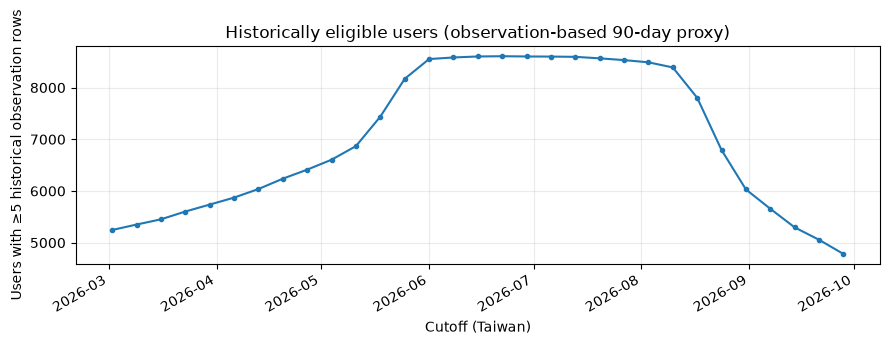

In [24]:
diagnostic_pool = examples if EVALUATE_HOLDOUT else examples.loc[examples.split.ne("holdout")]
disagreements=[]
for target in TARGETS:
    a = diagnostic_pool[f"y_{target}"].to_numpy(dtype=bool)
    b = diagnostic_pool[f"seen_{target}"].to_numpy(dtype=bool)
    disagreements.append({
        "target":target, "user_weeks":len(diagnostic_pool),
        "event_time_positives":int(a.sum()), "seen_time_positives":int(b.sum()),
        "event_only":int((a & ~b).sum()), "seen_only":int((b & ~a).sum()),
        "discordant_user_weeks":int((a != b).sum()),
        "jaccard":round(float((a & b).sum()/(a | b).sum()),4) if (a | b).any() else np.nan,
    })
disagreement_df=pd.DataFrame(disagreements)
display(disagreement_df)
print("NOTE: These are *candidate-label* disagreements, not verified classification mistakes.")

eligible_by_week=(examples.groupby(["cutoff_tw","split"],as_index=False)
    .agg(eligible_users=("eligible_proxy","sum"),all_cohort=("UserID","size")))
display(eligible_by_week.tail(12))
if len(eligible_by_week):
    fig,ax=plt.subplots(figsize=(9,3.4))
    ax.plot(eligible_by_week.cutoff_tw.dt.tz_localize(None),
            eligible_by_week.eligible_users,marker=".")
    ax.set(title="Historically eligible users (observation-based 90-day proxy)",
           xlabel="Cutoff (Taiwan)",ylabel="Users with ≥5 historical observation rows")
    ax.grid(alpha=.25)
    fig.autofmt_xdate(); fig.tight_layout();plt.show()

## 11 — Candidate positive rates by split, **without opening the holdout**

Train and validation class prevalences help plan models and thresholds. These are **retrospective candidate rates**, not actual official-test prevalences. Because the sample population can change with the 90-day eligibility proxy, report both all-cohort and proxy-eligible rates.

Leave the holdout sealed: it should not be used to decide features, thresholds, or model choice.

In [25]:
rate_records=[]
for (split,eligible), group in diagnostic_pool.groupby(["split","eligible_proxy"],sort=False):
    for target in TARGETS:
        rate_records.append({"split":split,"eligible_proxy":bool(eligible),"target":target,
                             "user_weeks":len(group),
                             "event_candidate_pos_pct":round(100*group[f"y_{target}"].mean(),3),
                             "seen_proxy_pos_pct":round(100*group[f"seen_{target}"].mean(),3)})
rates_df=pd.DataFrame(rate_records)
display(rates_df)

# For train-vs-validation diagnostics, do not inadvertently include holdout future positives.
val_rates=rates_df.loc[rates_df.eligible_proxy].pivot(index="target",columns="split",values="event_candidate_pos_pct")
if {"train","validation"}.issubset(val_rates.columns):
    val_rates["validation_minus_train_pp"]=val_rates.validation-val_rates.train
    display(val_rates.sort_values("validation_minus_train_pp"))

,split,eligible_proxy,target,user_weeks,event_candidate_pos_pct,seen_proxy_pos_pct
0,train,True,open_pr,158269,13.610,13.680
1,train,True,open_issue,158269,5.816,6.185
2,train,True,issue_comment,158269,8.578,8.578
3,train,True,pr_review,158269,7.506,7.506
4,train,True,pr_review_comment,158269,4.931,4.931
5,train,True,push,158269,57.671,57.671
6,train,False,open_pr,39731,4.775,4.752
7,train,False,open_issue,39731,1.847,1.777
8,train,False,issue_comment,39731,1.515,1.515
9,train,False,pr_review,39731,0.783,0.783


split,train,validation,validation_minus_train_pp
target,,,
push,57.671,23.227,-34.444
open_pr,13.610,4.458,-9.152
issue_comment,8.578,3.456,-5.122
pr_review,7.506,2.720,-4.786
open_issue,5.816,2.736,-3.080
pr_review_comment,4.931,1.856,-3.075


## 12 — Compare candidate labels to instructor-provided *example truth* (optional)

Only when `RUN_SAMPLE_TRUTH_CHECK=True`, if `assignment2/evaluation/examples/sample_truth.csv` is present, we can compare candidates to **the example labeled week of 9/27**. The README does not specify that week's exact day-boundaries or timezone. Therefore two plausible interpretations are tested: `2026-09-27 00:00` Taiwan and UTC. This is a **diagnostic sensitivity check**, *not a definitive ground-truth audit* or permission to reverse-engineer the unpublished final labels.

**Crucial distinction:** the example truth may include label events not inferable from the eight relational entity tables, especially if PR/issue rows are discovered indirectly. The example week overlaps the default historical holdout period: leave this check **disabled by default** to avoid holdout contamination, or explicitly designate a different untouched holdout before enabling it. A higher example agreement score suggests an interpretation worth investigating, not proof of a universal definition. We use the **official evaluator** for comparing complete six-label candidate matrices; exact-match and discordant counts are reported by activity.

If the sample file does not exist, the cell skips cleanly.

In [26]:
sample_truth_path=OFFICIAL_REPO/"evaluation/examples/sample_truth.csv"
sample_match_rows=[]
if RUN_SAMPLE_TRUTH_CHECK and sample_truth_path.is_file():
    sample_truth=pd.read_csv(sample_truth_path)
    assert list(sample_truth.columns)==["UserID",*TARGETS]
    if sample_truth.UserID.duplicated().any():
        raise ValueError("Official example sample_truth.csv has repeated UserIDs")
    for interpretation,start in [("Sep27 Taiwan 00",taiwan_monday("2026-09-27").tz_convert("UTC")),
                                 ("Sep27 UTC 00",pd.Timestamp("2026-09-27T00:00:00Z"))]:
        end=start+pd.Timedelta(days=7)
        for variant in ("event_time","seen_time"):
            pred=sample_truth[["UserID"]].copy()
            for target in TARGETS:
                pred[target]=pred.UserID.isin(label_ones(target,start,end,variant)).astype(int)
            got=official.scores(pred,sample_truth)
            sample_match_rows.append({"interpretation":interpretation,"label_variant":variant,
                "sample_users":len(pred),**got})
            for target in TARGETS:
                sample_match_rows[-1]["mismatch_"+target]=int((pred[target]!=sample_truth[target]).sum())
    sample_match_df=pd.DataFrame(sample_match_rows)
    display(sample_match_df)
    print("These are *candidate vs example truth* scores, NOT predictions of future GitHub behavior.")
else:
    print("No sample truth check requested or no evaluation/examples/sample_truth.csv found.")

,interpretation,label_variant,sample_users,macro_f1,micro_f1,score,mismatch_open_pr,mismatch_open_issue,mismatch_issue_comment,mismatch_pr_review,mismatch_pr_review_comment,mismatch_push
0,Sep27 Taiwan 00,event_time,4785,0.963868,0.961534,0.962701,48,26,36,19,19,195
1,Sep27 Taiwan 00,seen_time,4785,0.952420,0.955987,0.954204,54,70,36,20,19,195
2,Sep27 UTC 00,event_time,4785,0.978851,0.978938,0.978894,33,20,18,11,9,97
3,Sep27 UTC 00,seen_time,4785,0.966765,0.972991,0.969878,40,66,18,12,9,97


These are *candidate vs example truth* scores, NOT predictions of future GitHub behavior.


In [31]:
if RUN_SAMPLE_TRUTH_CHECK and sample_truth_path.is_file():
    truth = pd.read_csv(sample_truth_path)

    rows = []

    for start_name, start in [
        ("Taiwan", pd.Timestamp("2026-09-27", tz=TZ).tz_convert("UTC")),
        ("UTC", pd.Timestamp("2026-09-27", tz="UTC")),
    ]:
        end = start + pd.Timedelta(days=7)

        for variant in ("event_time", "seen_time"):
            for target in TARGETS:
                predicted_ids = label_ones(target, start, end, variant)

                predicted = truth["UserID"].isin(predicted_ids)
                actual = truth[target].eq(1)

                tp = int((predicted & actual).sum())
                fp = int((predicted & ~actual).sum())
                fn = int((~predicted & actual).sum())
                tn = int((~predicted & ~actual).sum())

                rows.append({
                    "start": start_name,
                    "variant": variant,
                    "target": target,
                    "TP": tp,
                    "FP": fp,
                    "FN": fn,
                    "TN": tn,
                    "mismatches": fp + fn,
                    "precision": tp / (tp + fp) if tp + fp else 0,
                    "recall": tp / (tp + fn) if tp + fn else 0,
                })

    verification_df = pd.DataFrame(rows)
    display(verification_df)

,start,variant,target,TP,FP,FN,TN,mismatches,precision,recall
0,Taiwan,event_time,open_pr,553,9,39,4184,48,0.983986,0.934122
1,Taiwan,event_time,open_issue,317,10,16,4442,26,0.969419,0.951952
2,Taiwan,event_time,issue_comment,426,12,24,4323,36,0.972603,0.946667
3,Taiwan,event_time,pr_review,408,4,15,4358,19,0.990291,0.964539
4,Taiwan,event_time,pr_review_comment,290,5,14,4476,19,0.983051,0.953947
5,Taiwan,event_time,push,2293,126,69,2297,195,0.947912,0.970787
6,Taiwan,seen_time,open_pr,554,16,38,4177,54,0.971930,0.935811
7,Taiwan,seen_time,open_issue,308,45,25,4407,70,0.872521,0.924925
8,Taiwan,seen_time,issue_comment,426,12,24,4323,36,0.972603,0.946667
9,Taiwan,seen_time,pr_review,408,5,15,4357,20,0.987893,0.964539


## 13 — Official F1 for **simple observable baselines** on historical validation weeks

To verify that the split and metric code work, score two **non-trained** baselines against the selected candidate target labels:

- **All-zero:** predicts nobody acts; intentionally weak but important as a metric sanity check.
- **Previous-week persistence:** predicts activity=1 iff a relevant row was *observable* in `[t−7d,t)`. This construction obeys feature-availability timing. It does not use labels from the future.

Both models are scored **one week at a time** with the official `scores` and `f1_per_event` functions. We report validation primarily; training is shown for context. Holdout scoring is OFF by default.

**This is not a trained model benchmark**: the labels for the three entity/review targets are uncertain, and the previous-week flags are crude. Large F1 values for zero-positive classes should be read with the instructor's unusual F1 convention in mind.

In [27]:
baseline_scores=[]
per_target_scores=[]
allowed_splits={"train","validation"}|({"holdout"} if EVALUATE_HOLDOUT else set())
for t_tw,group in examples.groupby("cutoff_tw",sort=True):
    split=group["split"].iloc[0]
    if split not in allowed_splits:
        continue
    for population, subset in [("all_cohort",group),("eligible_proxy",group.loc[group.eligible_proxy])]:
        if not len(subset):
            continue
        truth=subset[["UserID"]].copy()
        for target in TARGETS:
            truth[target]=subset[f"y_{target}"].astype("int8").to_numpy()
        for baseline in ("all_zero","previous_week"):
            pred=truth[["UserID"]].copy()
            for target in TARGETS:
                pred[target]= (np.zeros(len(subset),dtype="int8") if baseline=="all_zero"
                               else subset[f"prior7_{target}"].astype("int8").to_numpy())
            assert not pred.UserID.duplicated().any()
            got=official.scores(pred,truth)
            baseline_scores.append({"cutoff_tw":t_tw,"split":split,"population":population,
                                    "baseline":baseline,"users":len(subset),**got})
            for target,value in zip(TARGETS,official.f1_per_event(pred,truth)):
                per_target_scores.append({"cutoff_tw":t_tw,"split":split,"population":population,
                                          "baseline":baseline,"target":target,"f1":value})
baseline_df=pd.DataFrame(baseline_scores)
per_target_df=pd.DataFrame(per_target_scores)
print("Official per-week F1 scores, summarised across weeks (NOT pooled official submission score):")
display(baseline_df.groupby(["split","population","baseline"])[["macro_f1","micro_f1","score"]]
        .agg(["mean","median","min","max"]).round(4))
print("Official per-target F1 (median weekly), validation/proxy-eligible only:")
validation_target=per_target_df.loc[(per_target_df.split=="validation") &
                                    (per_target_df.population=="eligible_proxy")]
display(validation_target.groupby(["target","baseline"]).f1.median().unstack().round(4))

# Verify that holdout scores are not accidentally exposed.
if not EVALUATE_HOLDOUT:
    assert "holdout" not in set(baseline_df.split)
    print("PASS: Historical holdout performance was not scored or displayed.")

Official per-week F1 scores, summarised across weeks (NOT pooled official submission score):


macro_f1                          \
                                            mean  median     min     max   
split      population     baseline                                         
train      all_cohort     all_zero        0.0000  0.0000  0.0000  0.0000   
                          previous_week   0.4368  0.4442  0.2477  0.5988   
           eligible_proxy all_zero        0.0000  0.0000  0.0000  0.0000   
                          previous_week   0.4475  0.4738  0.2483  0.6140   
validation all_cohort     all_zero        0.0000  0.0000  0.0000  0.0000   
                          previous_week   0.2410  0.2420  0.2138  0.2722   
           eligible_proxy all_zero        0.0000  0.0000  0.0000  0.0000   
                          previous_week   0.2434  0.2424  0.2192  0.2731   

                                        micro_f1                          \
                                            mean  median     min     max   
split      population     baseline                                         
train      all_cohort     all_zero        0.0000  0.0000  0.0000  0.0000   
                          previous_week   0.6299  0.6302  0.5762  0.6652   
           eligible_proxy all_zero        0.0000  0.0000  0.0000  0.0000   
                          previous_week   0.6449  0.6495  0.5958  0.6777   
validation all_cohort     all_zero        0.0000  0.0000  0.0000  0.0000   
                          previous_week   0.4527  0.4814  0.2424  0.5481   
           eligible_proxy all_zero        0.0000  0.0000  0.0000  0.0000   
                          previous_week   0.4575  0.4860  0.2493  0.5498   

                                          score                          
                                           mean  median     min     max  
split      population     baseline                                       
train      all_cohort     all_zero       0.0000  0.0000  0.0000  0.0000  
                          previous_week  0.5334  0.5323  0.4359  0.6285  
           eligible_proxy all_zero       0.0000  0.0000  0.0000  0.0000  
                          previous_week  0.5462  0.5539  0.4369  0.6459  
validation all_cohort     all_zero       0.0000  0.0000  0.0000  0.0000  
                          previous_week  0.3469  0.3530  0.2281  0.4096  
           eligible_proxy all_zero       0.0000  0.0000  0.0000  0.0000  
                          previous_week  0.3504  0.3560  0.2342  0.4112

Official per-target F1 (median weekly), validation/proxy-eligible only:


baseline,all_zero,previous_week
target,,
issue_comment,0.0,0.1820
open_issue,0.0,0.2575
open_pr,0.0,0.1463
pr_review,0.0,0.1735
pr_review_comment,0.0,0.1629
push,0.0,0.5641


PASS: Historical holdout performance was not scored or displayed.


## 14 — Explicit point-in-time and split integrity audit

This notebook does not train a learned model. Nevertheless, verify invariants before implementing `src/temporal_dataset.py`:

1. Every user-week occurs exactly once; all `UserID`s are stable GitHub IDs and are members of the cohort.
2. Feature proxies contain only rows with `seen_utc < cutoff`; label candidates contain only timestamps in `[cutoff, cutoff+7d)`.
3. Calendar split windows are chronological and do not overlap across train/validation/holdout.
4. No later-known state (`merged_at`, `merged_by_id`, `closed_at`, `state_reason`, `dismissed_at`) is loaded.
5. A missing event timestamp does **not** automatically imply verified negative truth.
6. Latest snapshot and labeling assumptions are retained for future comparison.

The following is an inexpensive deterministic audit. For future model features, add tests that perturb events after t and verify feature vectors for t are unchanged.

In [28]:
checks = {}
checks["all_users_are_cohort"] = bool(examples.UserID.isin(cohort_user_ids).all())
checks["unique_user_cutoff"] = bool(~examples.duplicated(["UserID","cutoff_tw"]).any())
labelled = examples if EVALUATE_HOLDOUT else examples.loc[examples.split.ne("holdout")]
checks["six_binary_labels"] = bool(labelled[[f"y_{k}" for k in TARGETS]].isin([0,1]).all().all())
checks["no_null_labels"] = bool(labelled[[f"y_{k}" for k in TARGETS]].notna().all().all())
checks["holdout_labels_sealed"] = bool(EVALUATE_HOLDOUT or
    examples.loc[examples.split.eq("holdout"),[f"y_{k}" for k in TARGETS]].isna().all().all())
checks["chronological_splits"] = bool(calendar.loc[calendar.split.eq("train"),"label_end_utc"].max()
    <= calendar.loc[calendar.split.eq("validation"),"cutoff_utc"].min()
    and calendar.loc[calendar.split.eq("validation"),"label_end_utc"].max()
    <= calendar.loc[calendar.split.eq("holdout"),"cutoff_utc"].min())
checks["all_label_windows_mature_by_buffer"] = bool((calendar.label_end_utc +
    pd.Timedelta(days=LABEL_MATURATION_DAYS) <= SEEN_LAST_UTC).all())
checks["feature_sources_use_seen_time"] = all(s[2] in ("first_seen_at","created_at") for s in SPECS.values())
checks["no_future_known_columns_read"] = all(not ({"merged_at","merged_by_id","closed_at","state_reason","dismissed_at"}&set(v)) for v in COLS.values())
# Prove that the 7d prior-activity flags equal sets derived solely from seen timestamps.
checks["past_only_last_week_flags"] = True
for t in calendar.cutoff_utc:
    row=examples.loc[examples.cutoff_tw.eq(t.tz_convert(TZ))]
    for sig in TARGETS:
        expected=row.UserID.isin(prior_observation_ones(sig,t,7)).astype("int8").to_numpy()
        if not np.array_equal(row[f"prior7_{sig}"].to_numpy(),expected):
            checks["past_only_last_week_flags"]=False
            break
check_df=pd.DataFrame({"test":list(checks),"passed":list(checks.values())})
display(check_df)
assert all(checks.values()), "One or more critical historical-data checks failed"
print("All invariants passed; this does not prove candidate labels are identical to the TAs' ground truth.")

,test,passed
0,all_users_are_cohort,True
1,unique_user_cutoff,True
2,six_binary_labels,True
3,no_null_labels,True
4,holdout_labels_sealed,True
5,chronological_splits,True
6,all_label_windows_mature_by_buffer,True
7,feature_sources_use_seen_time,True
8,no_future_known_columns_read,True
9,past_only_last_week_flags,True


All invariants passed; this does not prove candidate labels are identical to the TAs' ground truth.


## 15 — Optional local export for later models (OFF by default)

To avoid accidentally committing derived data or files whose semantics may change, exports are disabled unless you set `EXPORT_LOCAL_FILES=True`. Exported CSVs **include provisional candidate labels** and an explicit `label_variant` naming convention. They are never called `truth.csv` and must **not** be submitted as official predictions.

The export is per-split, uses stable GitHub `UserID`, and includes the release SHA in a provenance metadata text file. Place derived outputs under `experiments/derived/` and ignore them in Git unless the project deliberately commits compact, non-sensitive summary reports. The `assignment2/` instructor folder is never modified.

In [29]:
if EXPORT_LOCAL_FILES:
    out=PROJECT_ROOT/"experiments/derived"
    out.mkdir(parents=True,exist_ok=True)
    for split, frame in examples.groupby("split"):
        output=out/f"historical_candidates_{split}.csv"
        frame.to_csv(output,index=False)
        print("Saved",output,"rows",len(frame))
    provenance=("Purpose: candidate historical labels and seven-day persistence proxies; not official truth.\n"
                f"Dataset repo SHA: {RELEASE_SHA}\n"
                f"Latest cohort observation UTC: {SEEN_LAST_UTC}\n"
                f"Splits: validation {VALID_START_TW}, holdout {HOLDOUT_START_TW}\n"
                f"Maturation days: {LABEL_MATURATION_DAYS}\n"
                "DO NOT use candidate labels as official ground truth.\n")
    (out/"provenance.txt").write_text(provenance,encoding="utf-8")
else:
    print("Export OFF: notebook did not write derived files.")

Export OFF: notebook did not write derived files.


## 16 — Findings and engineering handoff (complete after executing)

### How to interpret the notebook results

- A structurally valid chronological split is **necessary but not sufficient** for correct learning.
- Low label disagreement means the *two chosen proxies* agree; it does **not** establish they both agree with the true GitHub event semantics.
- The official sample truth is the best available small reference, but `week of 9/27` is underspecified in the README; inspect multiple plausible interval boundaries and investigate any remaining discrepancy.
- The **actual official testing population** is the Oct 28 release's `test_input.csv`. A historical `>=5 records / 90 days` approximation is only a proxy. Never add actual future truth to training.
- Baseline scores here are measured against **candidate historical labels**, not the sealed November test.
- The instructor's scorer awards F1=1 for classes absent in truth and prediction in a scored subset; examine per-target TP/FP/FN if some weeks show unusually high macro-F1.

### Suggested next implementation actions

1. Audit example-truth mismatches with *only* instructor data; identify which PR/issue/review labels are inferable and where labels remain ambiguous.
2. Freeze a label-spec decision in `EXPERIMENT_LOG.md` (signal, timestamp, actor column, inclusion/exclusion rule, missingness policy, limitations).
3. Freeze split dates and record the release SHA before comparing models. Do not tune hyperparameters against historical holdout labels.
4. Turn these audited functions into a tested `src/temporal_dataset.py` with explicit `t` and deterministic data selection.
5. Start with observable 7/30/90-day frequency and recency features; compare against these persistence and zero baselines on **validation** with the official evaluator.
6. Add relation-aware and time-aware enhancements only after the baseline is reproducible.
7. Append measured results and caveats to the single project `EXPERIMENT_LOG.md`; do not overwrite previous results from older snapshot SHAs.

### Daily update protocol

```
Instructor publishes new snapshot at 21:00 Taiwan
       │
       ├── Keep earlier experiment provenance and results
       ├── Re-clone only the ignored assignment2/ data repository
       ├── Restart notebook kernel
       ├── Run all cells; re-audit timestamps and candidate labels
       ├── Compare new output with prior release
       └── Append findings to EXPERIMENT_LOG.md
```

**Not an automated daily scheduler:** the notebook recalculates on rerun; it does not fetch data or run unattended.

In [30]:
print("=== CURRENT RUN / READ-ONLY HANDOFF ===")
print("Official commit:",RELEASE_SHA)
print("Observed cohort extent:",SEEN_FIRST_UTC,"through",SEEN_LAST_UTC)
print("Calendar windows:",len(calendar),"by split:",calendar.split.value_counts().to_dict())
print("Candidate-label disagreement (train+validation unless explicitly opened):")
display(disagreement_df[["target","event_time_positives","seen_time_positives","discordant_user_weeks","jaccard"]])
recent_eligible=eligible_by_week.iloc[-1]
print("Latest eligibility proxy:",int(recent_eligible.eligible_users),"of",int(recent_eligible.all_cohort),
      "at",recent_eligible.cutoff_tw)
print("Scoring source:",EVALUATOR_PATH)
print("Historical holdout scores opened:",EVALUATE_HOLDOUT)
print("Recommended next step: reconcile the ambiguous target labels before fitting models.")

=== CURRENT RUN / READ-ONLY HANDOFF ===
Official commit: 506d860693df60a698b68aa63a8edb4a984c8e1b
Observed cohort extent: 2025-12-01 00:01:12+00:00 through 2026-10-13 12:59:29+00:00
Calendar windows: 31 by split: {'train': 22, 'validation': 5, 'holdout': 4}
Candidate-label disagreement (train+validation unless explicitly opened):


,target,event_time_positives,seen_time_positives,discordant_user_weeks,jaccard
0,open_pr,25172,25243,769,0.9700
1,open_issue,10992,11429,2303,0.8137
2,issue_comment,15522,15522,0,1.0000
3,pr_review,13230,13230,18,0.9986
4,pr_review_comment,8692,8692,0,1.0000
5,push,107223,107223,0,1.0000


Latest eligibility proxy: 4782 of 9000 at 2026-09-28 00:00:00+08:00
Scoring source: c:\Users\Davon\Desktop\Master\Semester 3\535703 Big Data Analytics\Assignment 2\assignment2\evaluation\evaluate.py
Historical holdout scores opened: False
Recommended next step: reconcile the ambiguous target labels before fitting models.


In [32]:
start = pd.Timestamp("2026-09-27T00:00:00Z")
end = start + pd.Timedelta(days=7)

truth = pd.read_csv(sample_truth_path)
push_ids = label_ones("push", start, end, "event_time")

audit = truth[["UserID", "push"]].copy()
audit["reconstructed"] = audit["UserID"].isin(push_ids).astype(int)
audit = audit[audit["push"] != audit["reconstructed"]].copy()

audit["error_type"] = np.where(
    audit["reconstructed"] == 1,
    "false_positive",
    "false_negative"
)

display(audit.groupby("error_type").size())
display(audit.head(20))

# Inspect available event timestamps around the week boundaries.
mismatch_ids = set(audit["UserID"])
push_records = events["push"]

nearby = push_records.loc[
    push_records["UserID"].isin(mismatch_ids)
    & push_records["event_utc"].between(
        start - pd.Timedelta(days=1),
        end + pd.Timedelta(days=1)
    ),
    ["UserID", "event_utc", "seen_utc"]
].sort_values(["UserID", "event_utc"])

display(nearby.head(100))

error_type
false_negative    33
false_positive    64
dtype: int64

,UserID,push,reconstructed,error_type
12,9306,0,1,false_positive
218,377938,0,1,false_positive
258,481677,1,0,false_negative
278,523952,1,0,false_negative
317,645970,0,1,false_positive
333,687076,1,0,false_negative
341,713193,1,0,false_negative
439,1176680,0,1,false_positive
445,1212163,0,1,false_positive
498,1422024,0,1,false_positive


,UserID,event_utc,seen_utc
1624436,9306,2026-09-27 12:38:31+00:00,2026-09-27 12:38:31+00:00
1624439,9306,2026-09-27 12:39:59+00:00,2026-09-27 12:39:59+00:00
1620160,377938,2026-09-26 05:15:26+00:00,2026-09-26 05:15:26+00:00
1620404,377938,2026-09-26 08:20:38+00:00,2026-09-26 08:20:38+00:00
1623603,377938,2026-09-27 07:09:07+00:00,2026-09-27 07:09:07+00:00
...,...,...,...
1643813,36478298,2026-10-04 05:42:35+00:00,2026-10-04 05:42:35+00:00
1643815,36478298,2026-10-04 05:44:26+00:00,2026-10-04 05:44:26+00:00
1643837,36478298,2026-10-04 05:59:32+00:00,2026-10-04 05:59:32+00:00
1623849,39370150,2026-09-27 08:51:13+00:00,2026-09-27 08:51:13+00:00


In [33]:
# EXP-004: Diagnose push-label mismatches by event position

start = pd.Timestamp("2026-09-27T00:00:00Z")
end = start + pd.Timedelta(days=7)
day = pd.Timedelta(days=1)

truth = pd.read_csv(sample_truth_path)
push_records = events["push"]

candidate_ids = label_ones("push", start, end, "event_time")

audit = truth[["UserID", "push"]].copy()
audit["reconstructed"] = (
    audit["UserID"].isin(candidate_ids).astype(int)
)

audit = audit[audit["push"] != audit["reconstructed"]].copy()

audit["error_type"] = np.where(
    audit["reconstructed"] == 1,
    "false_positive",
    "false_negative"
)

# Only examine users with mismatched labels.
p = push_records.loc[
    push_records["UserID"].isin(audit["UserID"])
].copy()

# Separate events by position relative to the proposed week.
periods = {
    "before_24h": (start - day, start),
    "first_24h": (start, start + day),
    "middle_5d": (start + day, end - day),
    "last_24h": (end - day, end),
    "after_24h": (end, end + day),
}

for name, (lo, hi) in periods.items():
    counts = (
        p.loc[
            p["event_utc"].ge(lo)
            & p["event_utc"].lt(hi)
        ]
        .groupby("UserID")
        .size()
    )

    audit[name] = (
        audit["UserID"]
        .map(counts)
        .fillna(0)
        .astype(int)
    )

# Summary by mismatch type.
columns = list(periods)

display(
    audit.groupby("error_type")[columns]
    .agg(["sum", "max"])
)

# How many false positives have pushes in the middle five days?
fp = audit[audit["error_type"] == "false_positive"]

print(
    "False positives with middle-week pushes:",
    int((fp["middle_5d"] > 0).sum()),
    "/", len(fp)
)

# Inspect individual cases.
display(
    audit.sort_values(
        ["error_type", "middle_5d"],
        ascending=[True, False]
    ).head(30)
)

before_24h     first_24h     middle_5d     last_24h      \
                      sum max       sum max       sum max      sum max   
error_type                                                               
false_negative          2   1         0   0         0   0        0   0   
false_positive         51   5       102   6         0   0        0   0   

               after_24h      
                     sum max  
error_type                    
false_negative        66   8  
false_positive         5   2

False positives with middle-week pushes: 0 / 64


,UserID,push,reconstructed,error_type,before_24h,first_24h,middle_5d,last_24h,after_24h
258,481677,1,0,false_negative,0,0,0,0,1
278,523952,1,0,false_negative,0,0,0,0,8
333,687076,1,0,false_negative,0,0,0,0,1
341,713193,1,0,false_negative,0,0,0,0,2
808,4501944,1,0,false_negative,0,0,0,0,1
877,5287911,1,0,false_negative,0,0,0,0,1
886,5373305,1,0,false_negative,0,0,0,0,2
935,5935107,1,0,false_negative,0,0,0,0,3
1043,7057691,1,0,false_negative,1,0,0,0,2
1065,7325699,1,0,false_negative,0,0,0,0,1


In [34]:
# Compare candidate week starts within +/- 24 hours.
# Diagnostic only: do not select a labeling rule by optimizing sample truth.

sample_push = push_records.loc[
    push_records["UserID"].isin(truth["UserID"])
    & push_records["event_utc"].ge(start - day)
    & push_records["event_utc"].lt(end + day)
]

results = []

for shift_hours in range(-24, 25):
    shifted_start = start + pd.Timedelta(hours=shift_hours)
    shifted_end = shifted_start + pd.Timedelta(days=7)

    active_ids = set(
        sample_push.loc[
            sample_push["event_utc"].ge(shifted_start)
            & sample_push["event_utc"].lt(shifted_end),
            "UserID"
        ]
    )

    pred = truth["UserID"].isin(active_ids)
    actual = truth["push"].eq(1)

    tp = int((pred & actual).sum())
    fp = int((pred & ~actual).sum())
    fn = int((~pred & actual).sum())

    results.append({
        "shift_hours": shift_hours,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "mismatches": fp + fn,
        "push_f1": (
            2 * tp / (2 * tp + fp + fn)
            if (2 * tp + fp + fn) else 1.0
        )
    })

sweep = pd.DataFrame(results)

display(
    sweep.sort_values(
        ["mismatches", "push_f1"],
        ascending=[True, False]
    ).head(15)
)

,shift_hours,TP,FP,FN,mismatches,push_f1
37,13,2362,0,0,0,1.000000
38,14,2359,2,3,5,0.998941
36,12,2356,6,6,12,0.997460
39,15,2346,6,16,22,0.995333
35,11,2352,13,10,23,0.995134
34,10,2349,17,13,30,0.993655
40,16,2342,11,20,31,0.993425
33,9,2347,24,15,39,0.991760
41,17,2336,15,26,41,0.991301
32,8,2346,31,16,47,0.990082


In [35]:
# EXP-004: Verify all six labels against official example truth
# using the newly identified 21:00 Taiwan window.

import importlib.util
import pandas as pd

truth = pd.read_csv(sample_truth_path)

evaluator_path = sample_truth_path.parent.parent / "evaluate.py"
spec = importlib.util.spec_from_file_location(
    "official_evaluator", evaluator_path
)
official = importlib.util.module_from_spec(spec)
spec.loader.exec_module(official)

windows = {
    "UTC midnight": pd.Timestamp("2026-09-27T00:00:00Z"),
    "Taiwan 21:00": pd.Timestamp("2026-09-27T13:00:00Z"),
}

results = []

for window_name, start in windows.items():
    end = start + pd.Timedelta(days=7)

    for variant in ["event_time", "seen_time"]:
        pred = truth[["UserID"]].copy()

        for target in official.EVENT_COLS:
            positive_users = label_ones(
                target, start, end, variant
            )

            pred[target] = (
                pred["UserID"]
                .isin(positive_users)
                .astype(int)
            )

        # Use the instructor's exact evaluator.
        score = official.scores(pred, truth)
        per_target = official.f1_per_event(pred, truth)

        for target, f1 in zip(
            official.EVENT_COLS, per_target
        ):
            mismatch = int(
                (pred[target] != truth[target]).sum()
            )

            results.append({
                "window": window_name,
                "variant": variant,
                "target": target,
                "f1": f1,
                "mismatches": mismatch,
                "official_positives": int(
                    truth[target].sum()
                ),
                "reconstructed_positives": int(
                    pred[target].sum()
                ),
                "combined_score": score["score"],
            })

verification = pd.DataFrame(results)

display(
    verification.sort_values(
        ["window", "variant", "target"]
    )
)

print("\nSUMMARY")
display(
    verification.groupby(
        ["window", "variant"]
    ).agg(
        total_mismatches=("mismatches", "sum"),
        combined_f1=("combined_score", "first"),
        mean_target_f1=("f1", "mean"),
    ).sort_values("total_mismatches")
)

,window,variant,target,f1,mismatches,official_positives,reconstructed_positives,combined_score
14,Taiwan 21:00,event_time,issue_comment,1.000000,0,450,450,0.999639
13,Taiwan 21:00,event_time,open_issue,0.997006,2,333,335,0.999639
12,Taiwan 21:00,event_time,open_pr,1.000000,0,592,592,0.999639
15,Taiwan 21:00,event_time,pr_review,1.000000,0,423,423,0.999639
16,Taiwan 21:00,event_time,pr_review_comment,1.000000,0,304,304,0.999639
17,Taiwan 21:00,event_time,push,1.000000,0,2362,2362,0.999639
20,Taiwan 21:00,seen_time,issue_comment,1.000000,0,450,450,0.990226
19,Taiwan 21:00,seen_time,open_issue,0.928571,50,333,367,0.990226
18,Taiwan 21:00,seen_time,open_pr,0.994123,7,592,599,0.990226
21,Taiwan 21:00,seen_time,pr_review,0.998819,1,423,424,0.990226



SUMMARY


total_mismatches  combined_f1  mean_target_f1
window       variant                                                  
Taiwan 21:00 event_time                 2     0.999639        0.999501
             seen_time                 58     0.990226        0.986919
UTC midnight event_time               188     0.978894        0.978851
             seen_time                242     0.969878        0.966765

In [36]:
# EXP-004: Investigate the two remaining open_issue mismatches

start = pd.Timestamp("2026-09-27T13:00:00Z")
end = start + pd.Timedelta(days=7)

truth = pd.read_csv(sample_truth_path)

predicted_ids = label_ones(
    "open_issue", start, end, "event_time"
)

audit = truth[["UserID", "open_issue"]].copy()
audit["reconstructed"] = (
    audit["UserID"].isin(predicted_ids).astype(int)
)

mismatches = audit.loc[
    audit["open_issue"] != audit["reconstructed"]
].copy()

print("Mismatching users:")
display(mismatches)

assert len(mismatches) == 2
assert (mismatches["open_issue"] == 0).all()
assert (mismatches["reconstructed"] == 1).all()

# Read original issue records, including stable GitHub issue IDs.
columns = [
    "github_issue_id",
    "repo_id",
    "number",
    "author_id",
    "is_pull_request",
    "created_at",
    "first_seen_at",
    "created_via_app",
]

issues = pd.read_parquet(
    DATA_DIR / "Issues.parquet",
    columns=columns
)

issues["UserID"] = issues["author_id"].map(actor_to_public)
issues["created_utc"] = pd.to_datetime(
    issues["created_at"], utc=True
)
issues["first_seen_utc"] = pd.to_datetime(
    issues["first_seen_at"], utc=True
)

affected = issues.loc[
    issues["UserID"].isin(mismatches["UserID"])
    & issues["created_utc"].ge(start)
    & issues["created_utc"].lt(end)
    & issues["is_pull_request"].eq(False)
].copy()

affected["observation_delay_hours"] = (
    affected["first_seen_utc"] - affected["created_utc"]
).dt.total_seconds() / 3600

affected["first_seen_after_window"] = (
    affected["first_seen_utc"] >= end
)

display(
    affected[
        [
            "UserID",
            "github_issue_id",
            "repo_id",
            "number",
            "created_utc",
            "first_seen_utc",
            "observation_delay_hours",
            "first_seen_after_window",
            "created_via_app",
        ]
    ].sort_values(["UserID", "created_utc"])
)

Mismatching users:


,UserID,open_issue,reconstructed
3141,101449496,0,1
3277,112989862,0,1


,UserID,github_issue_id,repo_id,number,created_utc,first_seen_utc,observation_delay_hours,first_seen_after_window,created_via_app
171534,101449496,5608729534,102827,241,2026-09-28 03:08:24+00:00,2026-10-10 05:11:20+00:00,290.048889,True,None
171409,112989862,5619458654,37821,344,2026-09-28 18:38:47+00:00,2026-10-09 17:36:51+00:00,262.967778,True,None


In [37]:
# EXP-004: Event-time labels with an observation cutoff

start = pd.Timestamp("2026-09-27T13:00:00Z")
end = start + pd.Timedelta(days=7)

truth = pd.read_csv(sample_truth_path)

observation_cutoffs = {
    "Week end": end,
    "Week end + 7 days": end + pd.Timedelta(days=7),
    "Week end + 14 days": end + pd.Timedelta(days=14),
    "No observation cutoff": None,
}

results = []

for cutoff_name, as_of in observation_cutoffs.items():
    pred = truth[["UserID"]].copy()

    for target in official.EVENT_COLS:
        e = events[target]

        # Actual activity occurred inside the example week.
        mask = (
            e["event_utc"].ge(start)
            & e["event_utc"].lt(end)
        )

        # Optional: require the corresponding record
        # to have been observable by the chosen cutoff.
        if as_of is not None:
            mask &= e["seen_utc"].le(as_of)

        positive_users = set(
            e.loc[mask, "UserID"].dropna()
        )

        pred[target] = (
            pred["UserID"]
            .isin(positive_users)
            .astype(int)
        )

        actual = truth[target].eq(1)
        predicted = pred[target].eq(1)

        results.append({
            "cutoff": cutoff_name,
            "target": target,
            "FP": int((predicted & ~actual).sum()),
            "FN": int((~predicted & actual).sum()),
            "mismatches": int((predicted != actual).sum()),
        })

    score = official.scores(pred, truth)

    print(
        f"{cutoff_name:24s} "
        f"Macro={score['macro_f1']:.6f} "
        f"Micro={score['micro_f1']:.6f} "
        f"Combined={score['score']:.6f}"
    )

results_df = pd.DataFrame(results)

display(
    results_df.pivot(
        index="target",
        columns="cutoff",
        values="mismatches"
    )
)

display(
    results_df.groupby("cutoff", sort=False)[
        ["FP", "FN", "mismatches"]
    ].sum()
)

Week end                 Macro=0.997974 Micro=0.999103 Combined=0.998538
Week end + 7 days        Macro=0.999501 Micro=0.999776 Combined=0.999639
Week end + 14 days       Macro=0.999501 Micro=0.999776 Combined=0.999639
No observation cutoff    Macro=0.999501 Micro=0.999776 Combined=0.999639


cutoff,No observation cutoff,Week end,Week end + 14 days,Week end + 7 days
target,,,,
issue_comment,0,0,0,0
open_issue,2,8,2,2
open_pr,0,0,0,0
pr_review,0,0,0,0
pr_review_comment,0,0,0,0
push,0,0,0,0


,FP,FN,mismatches
cutoff,,,
Week end,0,8,8
Week end + 7 days,2,0,2
Week end + 14 days,2,0,2
No observation cutoff,2,0,2


In [38]:
# EXP-004: Find the observation-time interval separating
# official positives from the two official negatives.

start = pd.Timestamp("2026-09-27T13:00:00Z")
end = start + pd.Timedelta(days=7)
week_plus_7 = end + pd.Timedelta(days=7)

truth = pd.read_csv(sample_truth_path)
truth_map = truth.set_index("UserID")["open_issue"]

e = events["open_issue"].copy()

# Issue creation occurred during the example week.
e = e.loc[
    e["event_utc"].ge(start)
    & e["event_utc"].lt(end)
    & e["UserID"].isin(truth["UserID"])
]

# Which users were reconstructable at week end?
available_at_end = set(
    e.loc[e["seen_utc"].le(end), "UserID"]
)

# Which users became reconstructable by end + 7 days?
available_at_plus7 = set(
    e.loc[e["seen_utc"].le(week_plus_7), "UserID"]
)

# Users added by allowing the extra observation period.
newly_visible = available_at_plus7 - available_at_end

detail = (
    e.loc[e["UserID"].isin(newly_visible)]
    .groupby("UserID", as_index=False)
    .agg(
        first_observed=("seen_utc", "min"),
        issue_count=("event_utc", "size"),
    )
)

detail["official_label"] = (
    detail["UserID"].map(truth_map)
)

detail = detail.sort_values("first_observed")

display(detail)

print("\nNewly visible users:", len(detail))

print("\nOfficial labels:")
display(detail["official_label"].value_counts())

# Can one observation cutoff separate the groups?
positive_times = detail.loc[
    detail["official_label"].eq(1),
    "first_observed"
]

negative_times = detail.loc[
    detail["official_label"].eq(0),
    "first_observed"
]

last_positive = positive_times.max()
first_negative = negative_times.min()

print("\nLast official positive observed:", last_positive)
print("First official negative observed:", first_negative)

if last_positive < first_negative:
    print("\nA separating observation cutoff EXISTS.")
    print("Candidate interval:")
    print(f"  >= {last_positive}")
    print(f"  <  {first_negative}")
else:
    print("\nNo single observation cutoff separates these users.")

,UserID,first_observed,issue_count,official_label
5,104238077,2026-10-04 23:03:10+00:00,1,1
6,108928239,2026-10-05 03:49:25+00:00,1,1
2,21228832,2026-10-06 18:19:56+00:00,1,1
9,121954209,2026-10-07 20:09:13+00:00,1,1
0,13179623,2026-10-08 00:57:24+00:00,1,1
3,40018640,2026-10-08 08:30:16+00:00,1,1
1,17217484,2026-10-08 09:42:07+00:00,1,1
8,117448747,2026-10-09 05:46:50+00:00,1,1
7,112989862,2026-10-09 17:36:51+00:00,1,0
4,101449496,2026-10-10 05:11:20+00:00,1,0



Newly visible users: 10

Official labels:


official_label
1    8
0    2
Name: count, dtype: int64


Last official positive observed: 2026-10-09 05:46:50+00:00
First official negative observed: 2026-10-09 17:36:51+00:00

A separating observation cutoff EXISTS.
Candidate interval:
  >= 2026-10-09 05:46:50+00:00
  <  2026-10-09 17:36:51+00:00


In [39]:
# EXP-004: Verify inferred historical snapshot cutoff

start = pd.Timestamp("2026-09-27T13:00:00Z")
end = start + pd.Timedelta(days=7)

truth = pd.read_csv(sample_truth_path)

cutoffs = {
    "Oct 8, 20:00 Taiwan":
        pd.Timestamp("2026-10-08T12:00:00Z"),

    "Oct 9, 20:00 Taiwan":
        pd.Timestamp("2026-10-09T12:00:00Z"),

    "Oct 9, 21:00 Taiwan":
        pd.Timestamp("2026-10-09T13:00:00Z"),

    "Oct 10, 20:00 Taiwan":
        pd.Timestamp("2026-10-10T12:00:00Z"),
}

results = []

for name, cutoff in cutoffs.items():
    pred = truth[["UserID"]].copy()

    for target in official.EVENT_COLS:
        e = events[target]

        mask = (
            e["event_utc"].ge(start)
            & e["event_utc"].lt(end)
            & e["seen_utc"].le(cutoff)
        )

        active_ids = set(e.loc[mask, "UserID"].dropna())
        pred[target] = (
            pred["UserID"].isin(active_ids).astype(int)
        )

    scores = official.scores(pred, truth)

    mismatches = {
        target: int((pred[target] != truth[target]).sum())
        for target in official.EVENT_COLS
    }

    results.append({
        "snapshot_cutoff": name,
        "macro_f1": scores["macro_f1"],
        "micro_f1": scores["micro_f1"],
        "combined_f1": scores["score"],
        "total_mismatches": sum(mismatches.values()),
        **mismatches,
    })

results_df = pd.DataFrame(results)
display(results_df)

assert results_df["total_mismatches"].min() >= 0

,snapshot_cutoff,macro_f1,micro_f1,combined_f1,total_mismatches,open_pr,open_issue,issue_comment,pr_review,pr_review_comment,push
0,"Oct 8, 20:00 Taiwan",0.999749,0.999888,0.999819,1,0,1,0,0,0,0
1,"Oct 9, 20:00 Taiwan",1.000000,1.000000,1.000000,0,0,0,0,0,0,0
2,"Oct 9, 21:00 Taiwan",1.000000,1.000000,1.000000,0,0,0,0,0,0,0
3,"Oct 10, 20:00 Taiwan",0.999501,0.999776,0.999639,2,0,2,0,0,0,0
